In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models

In [2]:
seed = 42
tf.random.set_seed(seed)
np.random.seed(seed)

In [3]:
from pathlib import Path
train_ds, val_ds = tf.keras.utils.audio_dataset_from_directory(
    directory=str(Path.home() / ".cache" / "ml-notebooks" / "speech-commands"),
    batch_size=64,
    validation_split=0.3,
    seed=seed,
    output_sequence_length=16000,
    subset='both'
)

Found 6505 files belonging to 4 classes.


Using 4554 files for training.


Using 1951 files for validation.


In [4]:
label = np.array(train_ds.class_names)
print(label)

['follow' 'learn' 'tree' 'visual']


In [5]:
def squeeze(audio, label):
    audio = tf.squeeze(audio, axis=-1)
    return audio, label

def get_spectogram(waveform):
    spectogram = tf.signal.stft(waveform, frame_length=255, frame_step=128)
    spectogram = tf.abs(spectogram)
    spectogram = spectogram[..., tf.newaxis]
    return spectogram

def make_spectogram_ds(ds):
    return ds.map(
        map_func=lambda audio, label: (get_spectogram(audio), label),
        num_parallel_calls=tf.data.AUTOTUNE
    )

In [6]:
train_ds = train_ds.map(squeeze, tf.data.AUTOTUNE)
val_ds = val_ds.map(squeeze, tf.data.AUTOTUNE)

test_ds = val_ds.shard(num_shards=2, index=0)
val_ds = val_ds.shard(num_shards=2, index=1)

In [7]:
train_spectogram_ds = make_spectogram_ds(train_ds)
val_spectogram_ds = make_spectogram_ds(val_ds)
test_spectogram_ds = make_spectogram_ds(test_ds)

In [8]:
for example_spectogram, example_spectogram_label, in train_spectogram_ds.take(1):
    break

input_shape = example_spectogram.shape[1:]
num_label = len(label)

In [9]:
norm_layer = layers.Normalization()
norm_layer.adapt(
    data=train_spectogram_ds.map(
        map_func=lambda spec, label:spec
    )
)

In [10]:
model = models.Sequential([
    layers.Input(shape=input_shape),
    layers.Resizing(32, 32),
    norm_layer,
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, activation='relu'),
    layers.MaxPooling2D(),
    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(num_label)
])

In [11]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 32, 32, 1)      │             3 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 64)     │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,179,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,255,431 (4.79 MB)

 Trainable params: 1,255,428 (4.79 MB)

 Non-trainable params: 3 (16.00 B)

In [12]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

In [13]:
history = model.fit(
    train_spectogram_ds,
    validation_data=val_spectogram_ds,
    epochs=8,
    callbacks=tf.keras.callbacks.EarlyStopping(verbose=1, patience=2)
)

Epoch 1/8


C:\Users\jorda\Code\ml-notebooks\courses\speech-recognition\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


 1/72 ━━━━━━━━━━━━━━━━━━━━ 3:05 3s/step - accuracy: 0.3125 - loss: 1.4278

 2/72 ━━━━━━━━━━━━━━━━━━━━ 4s 69ms/step - accuracy: 0.3281 - loss: 1.4480

 4/72 ━━━━━━━━━━━━━━━━━━━━ 3s 56ms/step - accuracy: 0.3516 - loss: 1.3647

 6/72 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.3776 - loss: 1.3233

... (288 outputs left out)

65/72 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9346 - loss: 0.1910

68/72 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9354 - loss: 0.1891

71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.9351 - loss: 0.1901

72/72 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.9348 - loss: 0.1906 - val_accuracy: 0.9448 - val_loss: 0.1706


In [14]:
for i, (spectogram_batch, label_batch) in enumerate(test_spectogram_ds):
    prediction = model.predict(spectogram_batch)

    for j in range(len(label_batch)):
        true_index = label_batch[j].numpy()
        predicted_index = np.argmax(prediction[j])

        print(f'Batch {i}, Data {j}: Original Label -> {label[true_index]}, Prediction -> {label[predicted_index]}')

1/2 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step 


Batch 0, Data 0: Original Label -> tree, Prediction -> tree
Batch 0, Data 1: Original Label -> learn, Prediction -> learn
Batch 0, Data 2: Original Label -> tree, Prediction -> follow
Batch 0, Data 3: Original Label -> follow, Prediction -> follow
Batch 0, Data 4: Original Label -> tree, Prediction -> tree
Batch 0, Data 5: Original Label -> follow, Prediction -> follow
Batch 0, Data 6: Original Label -> follow, Prediction -> follow
Batch 0, Data 7: Original Label -> follow, Prediction -> follow
Batch 0, Data 8: Original Label -> follow, Prediction -> follow
Batch 0, Data 9: Original Label -> learn, Prediction -> learn
Batch 0, Data 10: Original Label -> visual, Prediction -> visual
Batch 0, Data 11: Original Label -> learn, Prediction -> learn
Batch 0, Data 12: Original Label -> tree, Prediction -> tree
Batch 0, Data 13: Original Label -> follow, Prediction -> follow
Batch 0, Data 14: Original Label -> follow, Prediction -> follow
Batch 0, Data 15: Original Label -> tree, Prediction ->

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


Batch 1, Data 0: Original Label -> visual, Prediction -> visual
Batch 1, Data 1: Original Label -> tree, Prediction -> tree
Batch 1, Data 2: Original Label -> learn, Prediction -> learn
Batch 1, Data 3: Original Label -> tree, Prediction -> tree
Batch 1, Data 4: Original Label -> follow, Prediction -> follow
Batch 1, Data 5: Original Label -> visual, Prediction -> visual
Batch 1, Data 6: Original Label -> follow, Prediction -> follow
Batch 1, Data 7: Original Label -> tree, Prediction -> tree
Batch 1, Data 8: Original Label -> visual, Prediction -> visual
Batch 1, Data 9: Original Label -> visual, Prediction -> visual
Batch 1, Data 10: Original Label -> visual, Prediction -> visual
Batch 1, Data 11: Original Label -> follow, Prediction -> follow
Batch 1, Data 12: Original Label -> follow, Prediction -> follow
Batch 1, Data 13: Original Label -> learn, Prediction -> learn
Batch 1, Data 14: Original Label -> learn, Prediction -> learn
Batch 1, Data 15: Original Label -> follow, Predictio

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


... (38 outputs left out)

Batch 14, Data 0: Original Label -> tree, Prediction -> tree
Batch 14, Data 1: Original Label -> visual, Prediction -> visual
Batch 14, Data 2: Original Label -> follow, Prediction -> follow
Batch 14, Data 3: Original Label -> learn, Prediction -> learn
Batch 14, Data 4: Original Label -> follow, Prediction -> tree
Batch 14, Data 5: Original Label -> follow, Prediction -> follow
Batch 14, Data 6: Original Label -> visual, Prediction -> visual
Batch 14, Data 7: Original Label -> visual, Prediction -> visual
Batch 14, Data 8: Original Label -> follow, Prediction -> follow
Batch 14, Data 9: Original Label -> tree, Prediction -> tree
Batch 14, Data 10: Original Label -> follow, Prediction -> follow
Batch 14, Data 11: Original Label -> tree, Prediction -> tree
Batch 14, Data 12: Original Label -> follow, Prediction -> follow
Batch 14, Data 13: Original Label -> follow, Prediction -> follow
Batch 14, Data 14: Original Label -> tree, Prediction -> tree
Batch 14, Data 15: Original Label -> lea

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


Batch 15, Data 0: Original Label -> tree, Prediction -> tree
Batch 15, Data 1: Original Label -> visual, Prediction -> visual
Batch 15, Data 2: Original Label -> tree, Prediction -> tree
Batch 15, Data 3: Original Label -> tree, Prediction -> tree
Batch 15, Data 4: Original Label -> tree, Prediction -> tree
Batch 15, Data 5: Original Label -> follow, Prediction -> follow
Batch 15, Data 6: Original Label -> visual, Prediction -> visual
Batch 15, Data 7: Original Label -> visual, Prediction -> visual
Batch 15, Data 8: Original Label -> visual, Prediction -> visual
Batch 15, Data 9: Original Label -> learn, Prediction -> learn
Batch 15, Data 10: Original Label -> visual, Prediction -> visual
Batch 15, Data 11: Original Label -> learn, Prediction -> learn
Batch 15, Data 12: Original Label -> follow, Prediction -> follow
Batch 15, Data 13: Original Label -> learn, Prediction -> learn
Batch 15, Data 14: Original Label -> follow, Prediction -> follow
Batch 15, Data 15: Original Label -> learn

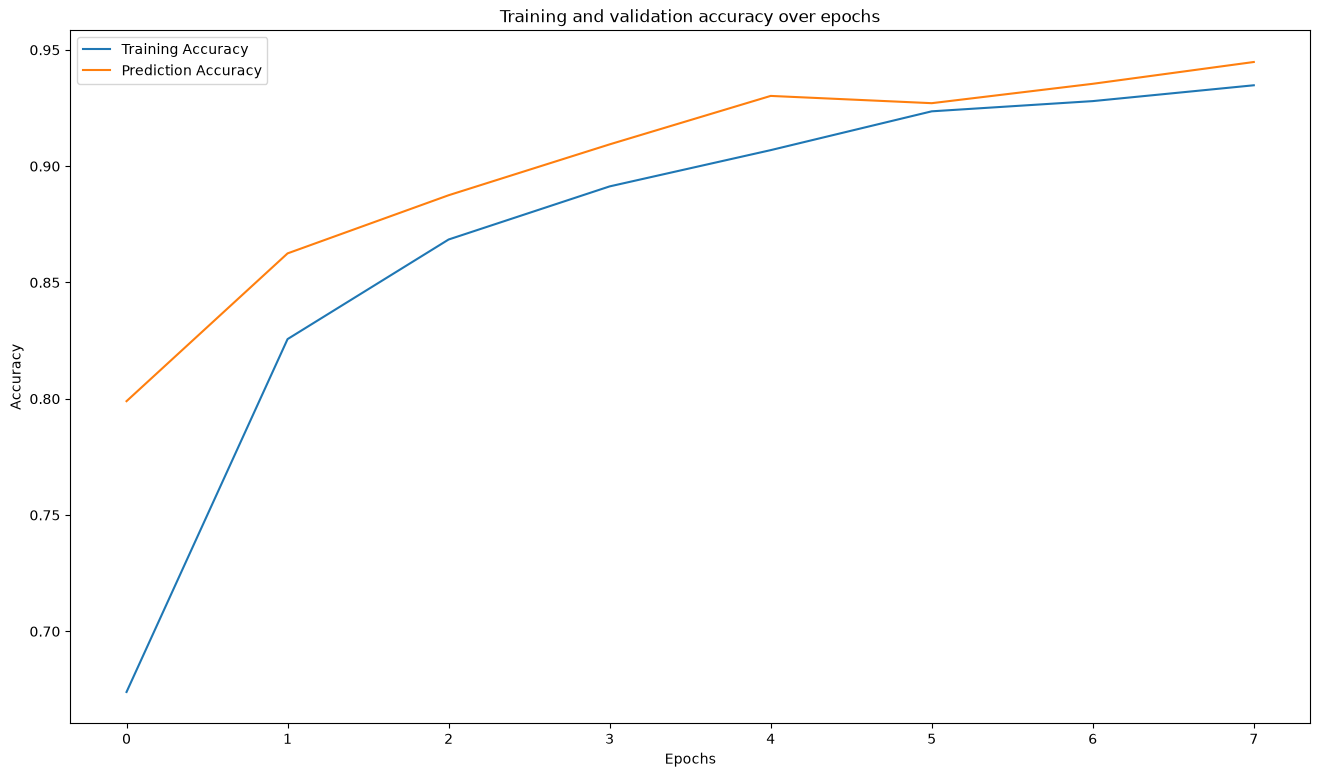

In [15]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epoch_range = range(len(acc))
plt.figure(figsize=(16, 9))
plt.plot(epoch_range, acc, label='Training Accuracy')
plt.plot(epoch_range, val_acc, label='Prediction Accuracy')
plt.title('Training and validation accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()